# PACTE ML — Prétraitement et analyse des images routières

## Objectif
Ce travail prépare les données nécessaires à la classification de cinq catégories d’objets routiers : voiture, piéton, vélo/cycliste, moto et bus. La méthode repose sur le contrôle de l’intégrité des images, la recherche de doublons, l’examen de la séparation des données et la normalisation des pixels.

Le jeu étudié contient **5 000 images réelles recadrées**, réparties entre entraînement et test. Il provient de Traffic-Object, COCO, Penn–Fudan et d’une collection initiale. Le fichier `dataset/sources.csv` conserve les sources, licences disponibles, recadrages et groupes de provenance.

Les images disponibles ont été sélectionnées et standardisées lors de la constitution du jeu. Les mesures présentées ici portent sur cet état d’entrée ; elles ne constituent pas un bilan chiffré avant/après des collections brutes.

## Périmètre et conformité au cahier des charges
Ce notebook couvre le **prétraitement et l’analyse exploratoire** : contrôle des fichiers, dédoublonnage MD5, vérification du format 128 × 128, normalisation et distribution des classes. Le contrôle des pixels et la recherche de similarités complètent le dédoublonnage MD5.

Le format retenu est celui autorisé sans dossier validation : **800 images d’entraînement et 200 images de test par classe**. La constitution de la validation depuis train, puis l’extraction HOG + histogrammes et la comparaison SVM / Random Forest / k-NN appartiennent aux étapes suivantes. Ce notebook ne constitue donc pas encore le livrable complet d’entraînement.

Les résultats numériques et les figures sont enregistrés dans le notebook. Les images originales sont conservées ; le filtrage produit une sélection en mémoire.

## 1. Environnement et chargement
L’exécution complète s’effectue de haut en bas dans un kernel Python neuf. Les versions des bibliothèques sont affichées pour assurer la traçabilité de l’environnement.

Dépendances : `numpy`, `Pillow`, `scipy`, `matplotlib` et `ipykernel`. Installation si nécessaire : `%pip install numpy Pillow scipy matplotlib ipykernel`.

Le répertoire `dataset` est recherché à partir du dossier courant et de ses parents. Les 20 images de `demo_scenes` sont exclues de l’analyse de classification : elles peuvent partager des sources avec l’entraînement et ne servent pas à mesurer les performances.

### Bloc de code 1 — Préparer l’environnement

**Rôle :** Charger les bibliothèques et retrouver le dossier des images.

**Ce qu’il utilise :** Le dossier du projet et les bibliothèques Python installées.

**Ce qu’il produit :** Les chemins `ROOT` et `DATASET`, les cinq classes et la taille cible. Les versions utilisées sont affichées.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
import csv, hashlib, random, platform
import importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fft import dctn
from scipy.ndimage import laplace

CLASSES = ('bus', 'car', 'cyclist', 'motorcycle', 'pedestrian')
SPLITS = ('train', 'validation', 'test')
SIZE = (128, 128)
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'dataset'/'train').is_dir() and (p/'dataset'/'test').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrir le notebook dans le dossier contenant dataset.")
DATASET = ROOT/'dataset'
print('Python :', platform.python_version())
print('Bibliothèques :', {p: importlib.metadata.version(p) for p in ['numpy', 'Pillow', 'scipy', 'matplotlib']})
print('Données :', DATASET)


Python : 3.13.9
Bibliothèques : {'numpy': '2.3.4', 'Pillow': '12.0.0', 'scipy': '1.16.3', 'matplotlib': '3.10.7'}
Données : C:\Users\lenovo\Desktop\MLProject\dataset


## 2. Méthode de contrôle

| Contrôle | Méthode | Interprétation |
|---|---|---|
| Intégrité | Ouverture et décodage complets | Un fichier illisible est exclu de la sélection. |
| Format | Dimensions, mode et format | La cible est un PNG RGB de 128 × 128 pixels. |
| Doublons de fichiers | Empreinte MD5 | Des empreintes identiques signalent des fichiers identiques. |
| Doublons de pixels | SHA-256 des pixels RGB et des dimensions | Détecte également des copies réencodées sans changement des pixels. |
| Similarité visuelle | pHash DCT de 64 bits, distance de Hamming ≤ 5 | Signale des candidats à vérifier visuellement, sans suppression automatique. |
| Séparation des sources | Comparaison des groupes de provenance | Recherche les groupes connus présents dans plusieurs splits. |
| Qualité visuelle | Variance du Laplacien et luminosité moyenne | Repère des cas de flou ou d’exposition à examiner. |

Les deux recherches de doublons exacts sont complémentaires : un même groupe peut apparaître dans les résultats MD5 et SHA-256. Leurs effectifs ne doivent pas être additionnés pour compter les images concernées.

La cellule de définition contient ses propres imports et constantes. Elle peut être exécutée indépendamment pour définir les fonctions ; le chargement des données reste nécessaire avant l’audit.

### Bloc de code 2 — Définir les outils de contrôle

**Rôle :** Décrire les opérations qui seront utilisées dans les blocs suivants.

**Ce qu’il utilise :** Les bibliothèques de lecture d’images, de calcul et de gestion des fichiers.

**Ce qu’il produit :** Trois fonctions : `normalized_pixels()` charge une image au format RGB 128 × 128 et ramène ses pixels entre 0 et 1 ; `perceptual_hash()` calcule une signature visuelle ; `audit_dataset()` parcourt les images et rassemble les contrôles.

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
import csv, hashlib, random, platform
import importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fft import dctn
from scipy.ndimage import laplace

CLASSES = ('bus', 'car', 'cyclist', 'motorcycle', 'pedestrian')
SPLITS = ('train', 'validation', 'test')
SIZE = (128, 128)

def normalized_pixels(path: Path) -> np.ndarray:
    """Charge une image RGB normalisée en mémoire, sans modifier le fichier."""
    with Image.open(path) as im:
        im = ImageOps.pad(ImageOps.exif_transpose(im).convert('RGB'), SIZE,
                          method=Image.Resampling.LANCZOS, color=(114, 114, 114))
        return np.asarray(im, dtype=np.float32) / 255.0

def perceptual_hash(im: Image.Image) -> int:
    gray = np.asarray(im.convert('L').resize((32, 32), Image.Resampling.LANCZOS), dtype=float)
    block = dctn(gray, type=2, norm='ortho')[:8, :8].ravel()
    bits = block > np.median(block[1:])
    return int(''.join('1' if bit else '0' for bit in bits), 2)

def audit_dataset(dataset, sources=None, phash_distance=5, blur_threshold=50.0):
    dataset = Path(dataset).resolve()
    if not 0 <= phash_distance <= 64 or blur_threshold < 0:
        raise ValueError('Invalid perceptual-hash or blur threshold')
    if not all((dataset / s).is_dir() for s in ('train', 'test')):
        raise ValueError(f'Expected train/ and test/ inside {dataset}')
    if sources is None:
        sources = next((p for p in (dataset/'sources.csv', dataset.parent/'sources.csv') if p.exists()), None)
    metadata, metadata_rows, metadata_fields = {}, [], []
    issues = []

    def issue(kind, image='', detail=''):
        issues.append(dict(kind=kind, image=image, detail=detail))

    if sources is not None:
        with Path(sources).open(encoding='utf-8-sig', newline='') as f:
            reader = csv.DictReader(f)
            metadata_fields = reader.fieldnames or []
            if not {'image', 'class', 'split', 'source_group'} <= set(metadata_fields):
                raise ValueError('sources.csv requires image, class, split and source_group columns')
            metadata_rows = list(reader)
        for row in metadata_rows:
            key = row['image'].replace('\\', '/')
            if key in metadata:
                issue('duplicate_metadata', key)
            metadata[key] = row
    else:
        issue('missing_provenance', detail='Cannot check known source groups without sources.csv')

    records = []
    for split in SPLITS:
        folder = dataset / split
        if not folder.exists():
            continue
        for cls in CLASSES:
            if not (folder / cls).is_dir():
                issue('missing_class_folder', f'{split}/{cls}')
        for path in sorted(folder.rglob('*')):
            if not path.is_file():
                continue
            relative = path.relative_to(dataset).as_posix()
            parts = Path(relative).parts
            if len(parts) != 3 or parts[1] not in CLASSES:
                issue('unexpected_path', relative, 'Expected split/class/image')
                continue
            row = dict(image=relative, split=split, **{'class': parts[1]}, readable=False,
                       width='', height='', mode='', format='', md5='', pixel_sha256='',
                       phash='', blur_score='', mean_brightness='', source_group='', error='')
            try:
                data = path.read_bytes()
                row['md5'] = hashlib.md5(data).hexdigest()
                with Image.open(path) as im:
                    im.load()
                    row.update(width=im.width, height=im.height, mode=im.mode, format=im.format)
                    rgb = ImageOps.exif_transpose(im).convert('RGB')
                    row['pixel_sha256'] = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
                    row['phash'] = f'{perceptual_hash(rgb):016x}'
                    # Résolution fixe pour comparer les scores de qualité.
                    gray = np.asarray(rgb.convert('L').resize(SIZE), dtype=np.float32)
                    row['blur_score'] = round(float(laplace(gray).var()), 4)
                    row['mean_brightness'] = round(float(gray.mean()), 4)
                row['readable'] = True
                if (row['width'], row['height'], row['mode'], row['format']) != (128, 128, 'RGB', 'PNG'):
                    issue('needs_standardization', relative, 'Expected 128x128 RGB PNG')
                if row['blur_score'] < blur_threshold:
                    issue('review_blur', relative, f"Laplacian variance={row['blur_score']}; heuristic only")
                if row['mean_brightness'] < 20 or row['mean_brightness'] > 235:
                    issue('review_exposure', relative, f"Mean brightness={row['mean_brightness']}; heuristic only")
            except (OSError, ValueError, SyntaxError, Image.DecompressionBombError) as exc:
                row['error'] = str(exc)
                issue('unreadable', relative, str(exc))
            source = metadata.get(relative)
            if source:
                row['source_group'] = source.get('source_group', '')
                if not row['source_group']:
                    issue('missing_source_group', relative)
                if source['class'] != row['class'] or source['split'] != split:
                    issue('metadata_label_mismatch', relative)
                if row['readable'] and source.get('pixel_sha256') and source['pixel_sha256'] != row['pixel_sha256']:
                    issue('provenance_hash_mismatch', relative)
            elif metadata_rows:
                issue('missing_metadata', relative)
            records.append(row)

    actual = {r['image'] for r in records}
    for missing in sorted(set(metadata) - actual):
        issue('metadata_image_missing', missing)
    duplicate_groups = []
    for key in ('md5', 'pixel_sha256'):
        groups = defaultdict(list)
        for row in records:
            if row[key]:
                groups[row[key]].append(row)
        for digest, group in groups.items():
            if len(group) > 1:
                duplicate_groups.append(dict(method=key, digest=digest,
                    images=[r['image'] for r in group],
                    cross_split=len({r['split'] for r in group}) > 1,
                    conflicting_labels=len({r['class'] for r in group}) > 1))

    near_pairs = []
    readable = [r for r in records if r['readable']]
    hashes = [int(r['phash'], 16) for r in readable]
    for i, row in enumerate(readable):
        for j in range(i):
            other = readable[j]
            if row['pixel_sha256'] == other['pixel_sha256']:
                continue  # Les doublons exacts sont comptabilisés séparément.
            distance = (hashes[i] ^ hashes[j]).bit_count()
            if distance <= phash_distance:
                near_pairs.append(dict(image_a=other['image'], image_b=row['image'],
                    hamming_distance=distance, cross_split=other['split'] != row['split']))
    group_members = defaultdict(list)
    for row in records:
        if row['source_group']:
            group_members[row['source_group']].append(row)
    source_overlap = [dict(source_group=key, images=[r['image'] for r in group],
                           splits=sorted({r['split'] for r in group}))
                      for key, group in group_members.items() if len({r['split'] for r in group}) > 1]
    counts = Counter((r['split'], r['class']) for r in records)
    count_rows = [dict(split=s, **{'class': c}, count=counts[s, c])
                  for s in SPLITS if (dataset/s).is_dir() for c in CLASSES]
    expected_counts = (not (dataset/'validation').exists()
                       and all(counts['train', c] == 800 and counts['test', c] == 200 for c in CLASSES))
    issue_counts = dict(Counter(r['kind'] for r in issues))
    blocking_kinds = set(issue_counts) - {'review_blur', 'review_exposure'}
    summary = dict(timestamp_utc=datetime.now(timezone.utc).isoformat(), dataset=str(dataset),
        provenance=str(Path(sources).resolve()) if sources is not None else None,
        total_files=len(records), readable_images=len(readable), unreadable_images=len(records)-len(readable),
        counts=count_rows, matches_800_train_200_test_per_class=expected_counts,
        file_duplicate_groups=sum(g['method'] == 'md5' for g in duplicate_groups),
        pixel_duplicate_groups=sum(g['method'] == 'pixel_sha256' for g in duplicate_groups),
        cross_split_duplicate_groups=sum(g['cross_split'] for g in duplicate_groups),
        near_duplicate_pairs=len(near_pairs), near_duplicate_cross_split_pairs=sum(p['cross_split'] for p in near_pairs),
        known_source_groups_crossing_splits=len(source_overlap), issue_counts=issue_counts,
        parameters=dict(size=list(SIZE), phash_distance=phash_distance, blur_threshold=blur_threshold),
        automated_checks_passed=not (blocking_kinds or duplicate_groups or near_pairs or source_overlap) and expected_counts,
        limitations='Visual labels and unknown source relationships are not certified. Blur/exposure and pHash flags require human review. Demo scenes excluded.')
    return dict(summary=summary, records=records, issues=issues, duplicate_groups=duplicate_groups,
                near_pairs=near_pairs, source_overlap=source_overlap, metadata=metadata,
                metadata_fields=metadata_fields, dataset=dataset)

### Bloc de code 3 — Lancer l’audit et afficher les résultats

**Rôle :** Appliquer les contrôles aux images présentes dans les dossiers de classification.

**Ce qu’il utilise :** `DATASET`, les fonctions du bloc précédent et le fichier de provenance.

**Ce qu’il produit :** `result` contient les résultats détaillés ; `summary` contient les nombres affichés : images lisibles, doublons, similarités et alertes.

In [3]:
result = audit_dataset(DATASET)
summary = result['summary']
print('Images examinées :', summary['total_files'])
print('Images lisibles :', summary['readable_images'])
print('Images illisibles :', summary['unreadable_images'])
print('Groupes de doublons MD5 :', summary['file_duplicate_groups'])
print('Groupes de doublons de pixels :', summary['pixel_duplicate_groups'])
print('Paires similaires à examiner :', summary['near_duplicate_pairs'])
print('Paires similaires entre train et test :', summary['near_duplicate_cross_split_pairs'])
print('Groupes source connus partagés entre splits :', summary['known_source_groups_crossing_splits'])
print('Alertes :', summary['issue_counts'])

Images examinées : 5000
Images lisibles : 5000
Images illisibles : 0
Groupes de doublons MD5 : 0
Groupes de doublons de pixels : 0
Paires similaires à examiner : 3
Paires similaires entre train et test : 0
Groupes source connus partagés entre splits : 0
Alertes : {'review_exposure': 1}


### Interprétation des résultats automatiques
Un effectif nul de doublons exacts signifie qu’aucune répétition n’a été détectée dans le jeu analysé par ces méthodes. Ce résultat est compatible avec une préparation préalable du jeu.

Les paires pHash constituent une catégorie distincte : elles peuvent représenter des objets différents de forme proche ou des images successives d’une même scène. Leur examen visuel est nécessaire avant toute exclusion. L’absence de chevauchement concerne les **groupes source connus** et ne garantit pas l’identification de toutes les scènes apparentées.

## 3. Analyse des similarités et prévention des fuites de données
Les paires signalées sont affichées avec leurs chemins et leur distance de Hamming. Le split est défini par le dossier actuel (`train` ou `test`), indépendamment des mots présents dans le nom du fichier source.

Une paire entre train et test peut biaiser l’évaluation. Une paire au sein d’un seul split ne crée pas cette fuite, mais peut surreprésenter une scène.

### Bloc de code 4 — Afficher les paires d’images similaires

**Rôle :** Comparer visuellement les images dont les signatures pHash sont proches.

**Ce qu’il utilise :** La liste `result["near_pairs"]` calculée par l’audit.

**Ce qu’il produit :** Une figure montrant chaque paire, ses chemins et sa distance de Hamming. Une petite distance indique une ressemblance, pas forcément une duplication.

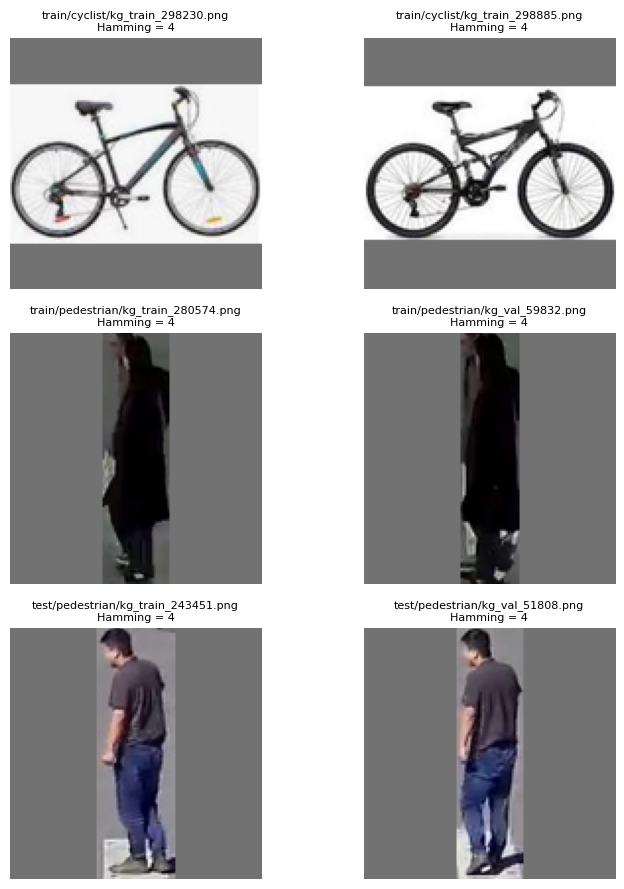

In [4]:
# Toutes les paires signalées (maximum 12 pour garder le notebook compact).
if result["near_pairs"]:
    import matplotlib.pyplot as plt
    from PIL import Image
    pairs = result["near_pairs"][:12]
    fig, axes = plt.subplots(len(pairs), 2, figsize=(8, 3 * len(pairs)), squeeze=False)
    for i, pair in enumerate(pairs):
        for j, key in enumerate(["image_a", "image_b"]):
            with Image.open(DATASET / pair[key]) as im:
                axes[i, j].imshow(im.copy())
            axes[i, j].set_title(pair[key] + "\nHamming = " + str(pair["hamming_distance"]), fontsize=8)
            axes[i, j].axis("off")
    fig.tight_layout()
    plt.show()
else:
    print("Aucune paire similaire signalée par ce contrôle.")

### Résultats de l’inspection visuelle
Trois paires sont signalées dans le jeu étudié :

| Paire | Observation | Traitement à retenir |
|---|---|---|
| Deux vélos dans train | Cadres et composants différents, composition similaire | Conservation des deux images ; similarité sans duplication apparente. |
| Deux piétons dans train | Même personne apparente, pose ou recadrage légèrement différent | Quasi-doublon probable ; exclusion d’un exemplaire à décider. |
| Deux piétons dans test | Même personne apparente sur deux vues proches | Quasi-doublon probable ; décision à fixer avant l’évaluation. |

Ces paires ne traversent pas la séparation train/test. Les exclusions manuelles ne sont pas appliquées dans cette exécution : la sélection conserve 5 000 images. Retirer un exemplaire de chaque paire de piétons conduirait à 4 998 images, dont 799 piétons train et 199 piétons test. Une variation des effectifs doit être documentée, sans ajout de copies pour rétablir l’équilibre.

## 4. Analyse de la distribution des classes
Les effectifs sont recalculés à partir des fichiers présents. Le tableau et le graphique permettent de vérifier l’équilibre entre les cinq catégories et le respect de la répartition 800/200 retenue.

### Bloc de code 5 — Compter et comparer les classes

**Rôle :** Vérifier si les classes sont équilibrées et si la répartition train/test respecte l’objectif.

**Ce qu’il utilise :** Les effectifs calculés par l’audit.

**Ce qu’il produit :** Un tableau et un graphique avec les nombres d’images par classe et par split.

| Classe | Train | Test | Total |
|---|---:|---:|---:|
| bus | 800 | 200 | 1000 |
| car | 800 | 200 | 1000 |
| cyclist | 800 | 200 | 1000 |
| motorcycle | 800 | 200 | 1000 |
| pedestrian | 800 | 200 | 1000 |


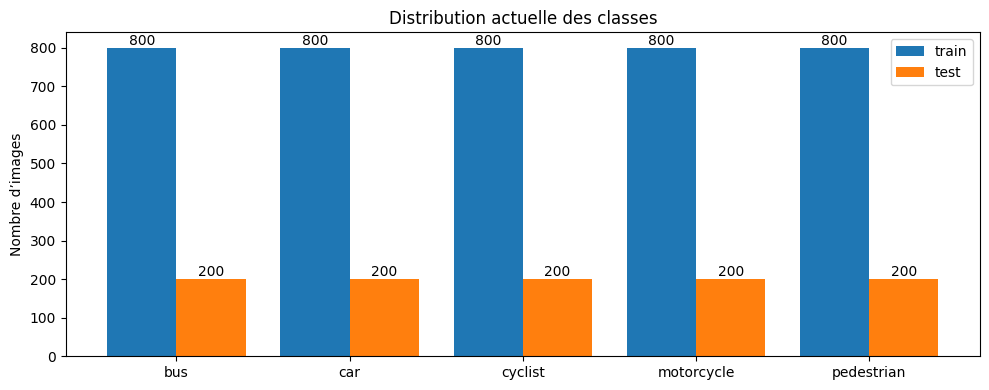

In [5]:
from IPython.display import Markdown, display
rows = summary['counts']
table = '| Classe | Train | Test | Total |\n|---|---:|---:|---:|\n'
for cls in CLASSES:
    train = sum(r['count'] for r in rows if r['class'] == cls and r['split'] == 'train')
    test = sum(r['count'] for r in rows if r['class'] == cls and r['split'] == 'test')
    table += f'| {cls} | {train} | {test} | {train + test} |\n'
display(Markdown(table))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

splits = [s for s in ["train", "validation", "test"] if (DATASET / s).is_dir()]
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(CLASSES))
width = 0.8 / len(splits)
for i, split in enumerate(splits):
    values = [sum(r["split"] == split and r["class"] == cls for r in result["records"]) for cls in CLASSES]
    bars = ax.bar(x + (i - (len(splits)-1)/2)*width, values, width, label=split)
    ax.bar_label(bars)
ax.set_xticks(x, CLASSES)
ax.set_ylabel("Nombre d’images")
ax.set_title("Distribution actuelle des classes")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Inspection d’un échantillon d’entraînement
Trois images par classe sont sélectionnées avec une graine fixe (`42`) pour rendre l’échantillonnage reproductible. L’inspection porte sur la cohérence de l’étiquette, la présence d’un objet principal et la qualité du recadrage. Cette revue partielle ne constitue pas une validation exhaustive des 5 000 annotations.

### Bloc de code 6 — Afficher un échantillon d’images

**Rôle :** Observer quelques exemples pour vérifier les objets, les étiquettes et les recadrages.

**Ce qu’il utilise :** Les images lisibles de train et une graine fixe de 42.

**Ce qu’il produit :** Une grille de trois images par classe. La graine permet de retrouver le même échantillon si le dataset ne change pas.

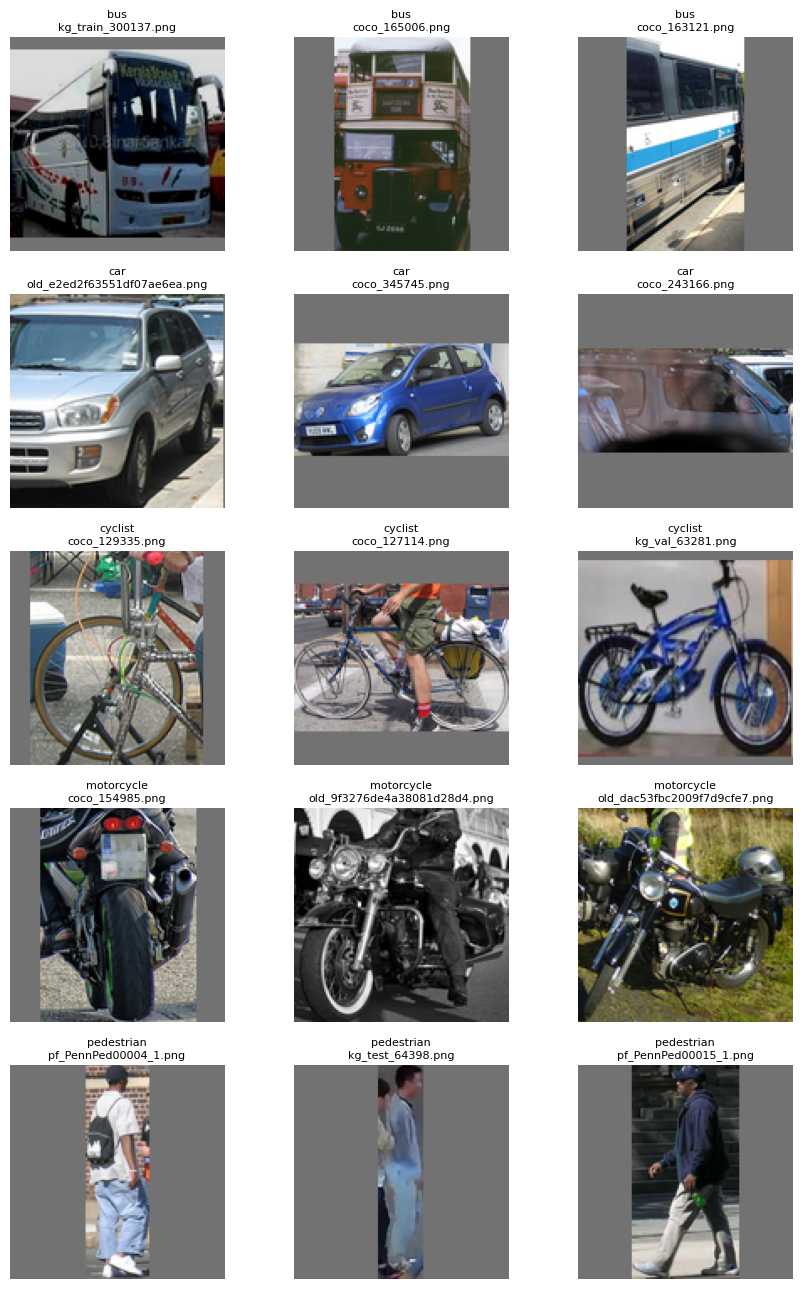

In [6]:
import random
rng = random.Random(42)
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(9, 13))
for row_index, cls in enumerate(CLASSES):
    candidates = [r for r in result["records"] if r["readable"] and r["split"] == "train" and r["class"] == cls]
    selected = rng.sample(candidates, min(3, len(candidates)))
    for j, ax in enumerate(axes[row_index]):
        ax.axis("off")
        if j < len(selected):
            with Image.open(DATASET / selected[j]["image"]) as im:
                ax.imshow(im.copy())
            ax.set_title(cls + "\n" + Path(selected[j]["image"]).name, fontsize=8)
fig.tight_layout()
plt.show()

## 6. Analyse des alertes de qualité
La netteté est estimée par la variance du Laplacien sur une image grise de 128 × 128 pixels. Un score inférieur à 50 déclenche une alerte exploratoire. La luminosité moyenne déclenche une alerte lorsqu’elle est inférieure à 20 ou supérieure à 235 sur l’échelle 0–255.

Ces seuils sont des heuristiques, pas des critères suffisants d’exclusion : le padding, un fond uniforme ou une scène nocturne influencent les scores. Les images signalées sont donc examinées visuellement.

### Bloc de code 7 — Afficher les alertes de qualité

**Rôle :** Examiner les fichiers signalés pour leur luminosité ou leur netteté.

**Ce qu’il utilise :** Les alertes de flou et d’exposition présentes dans `result["issues"]`.

**Ce qu’il produit :** Le nombre d’alertes, leurs détails et les images concernées, dans la limite de six exemples affichés.

Nombre d’alertes de qualité : 1
train/car/old_846ac4b00abcf1acbb63.png : Mean brightness=16.0709; heuristic only


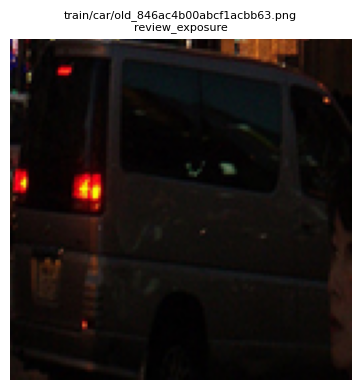

In [7]:
quality_flags = [r for r in result['issues'] if r['kind'] in {'review_blur', 'review_exposure'}]
print('Nombre d’alertes de qualité :', len(quality_flags))
if quality_flags:
    fig, axes = plt.subplots(1, min(6, len(quality_flags)), figsize=(4 * min(6, len(quality_flags)), 4), squeeze=False)
    for ax, flag in zip(axes.flat, quality_flags[:6]):
        with Image.open(DATASET/flag['image']) as im:
            ax.imshow(im.copy())
        ax.set_title(flag['image'] + '\n' + flag['kind'], fontsize=8)
        ax.axis('off')
        print(flag['image'], ':', flag['detail'])
    plt.tight_layout()
    plt.show()

### Observation
Une image de véhicule nocturne présente une faible luminosité. Le véhicule reste visible. L’image est conservée à ce stade ; sa pertinence doit être appréciée selon les conditions de prise de vue que le modèle devra traiter.

## 7. Filtrage des images illisibles et des doublons exacts
La sélection en mémoire applique les règles suivantes :

1. Exclusion des fichiers illisibles.
2. Regroupement des images ayant la même empreinte de pixels.
3. Mise à l’écart des groupes dont les étiquettes sont contradictoires.
4. Conservation d’un seul exemplaire pour les groupes de même classe, avec priorité test, puis validation, puis train.

Les originaux ne sont pas modifiés. Les quasi-doublons et les chevauchements de groupes source ne sont pas résolus par ce filtrage exact. Les effectifs avant et après sont affichés ; aucune exclusion automatique n’est attendue pour le jeu actuel.

### Bloc de code 8 — Construire la sélection nettoyée

**Rôle :** Retirer de la liste de travail les images illisibles et les copies exactes ; isoler les groupes aux étiquettes contradictoires.

**Ce qu’il utilise :** Les informations de lecture, les classes et les empreintes des pixels.

**Ce qu’il produit :** `clean_records` liste les images retenues ; `excluded` liste les exclusions avec leur raison. Les effectifs avant et après sont affichés.

In [8]:
groups = defaultdict(list)
excluded = []
for row in result['records']:
    if row['readable']:
        groups[row['pixel_sha256']].append(row)
    else:
        excluded.append((row['image'], 'illisible'))

clean_records = []
priority = {'test': 0, 'validation': 1, 'train': 2}
for group in groups.values():
    if len({r['class'] for r in group}) > 1:
        excluded.extend((r['image'], 'étiquettes contradictoires') for r in group)
    else:
        ordered = sorted(group, key=lambda r: (priority[r['split']], r['image']))
        clean_records.append(ordered[0])
        excluded.extend((r['image'], 'doublon exact') for r in ordered[1:])
print('Images avant filtrage :', len(result['records']))
print('Images après filtrage :', len(clean_records))
print('Images écartées de la liste :', len(excluded))
print('Fichiers modifiés ou supprimés : 0')
for path, reason in excluded[:20]:
    print(path, ':', reason)

Images avant filtrage : 5000
Images après filtrage : 5000
Images écartées de la liste : 0
Fichiers modifiés ou supprimés : 0


### Bilan du filtrage et traçabilité des exclusions

Le tableau compare les effectifs à l’entrée du filtrage et dans la sélection retenue, pour chaque classe et chaque split. La colonne « Exclues » mesure leur différence.

Le journal indique, pour chaque image écartée, son chemin, sa classe, son split et le motif. Une exclusion concerne la sélection en mémoire : elle ne correspond pas à une suppression du fichier original. Les alertes visuelles non suivies d’une exclusion ne figurent pas dans ce journal.

Les tableaux sont calculés à partir de cette exécution et conservés dans les sorties du notebook. Un journal vide signifie qu’aucune exclusion automatique n’a été nécessaire.

### Bloc de code 9 — Comparer les effectifs et établir le journal

**Rôle :** Présenter les changements produits par le filtrage et leur justification.

**Ce qu’il utilise :** Les images examinées (`result['records']`), les images retenues (`clean_records`) et les motifs enregistrés dans `excluded`.

**Ce qu’il produit :** Un tableau avant/après, des totaux par classe et un journal détaillé des exclusions. Les contrôles de cohérence vérifient que chaque image est soit conservée, soit exclue.

In [9]:
from collections import Counter
from html import escape
from IPython.display import HTML, display

def afficher_tableau(colonnes, lignes):
    entete = ''.join('<th>' + escape(str(c)) + '</th>' for c in colonnes)
    contenu = ''.join('<tr>' + ''.join('<td>' + escape(str(v)) + '</td>' for v in ligne) + '</tr>' for ligne in lignes)
    display(HTML('<table><thead><tr>' + entete + '</tr></thead><tbody>' + contenu + '</tbody></table>'))

avant = Counter((r['split'], r['class']) for r in result['records'])
apres = Counter((r['split'], r['class']) for r in clean_records)
splits_presents = [s for s in SPLITS if (DATASET/s).is_dir()]
comparaison = []
for classe in CLASSES:
    for split in splits_presents:
        a, b = avant[split, classe], apres[split, classe]
        comparaison.append([classe, split, a, b, a-b])
    a = sum(avant[s, classe] for s in splits_presents)
    b = sum(apres[s, classe] for s in splits_presents)
    comparaison.append([classe, 'Total classe', a, b, a-b])
comparaison.append(['Toutes les classes', 'Total général', len(result['records']), len(clean_records), len(excluded)])
display(HTML('<h4>Effectifs avant et après filtrage</h4>'))
afficher_tableau(['Classe', 'Split', 'Avant', 'Après', 'Exclues'], comparaison)

images_par_chemin = {r['image']: r for r in result['records']}
journal_exclusions = []
for chemin, motif in excluded:
    image = images_par_chemin[chemin]
    journal_exclusions.append({
        'image': chemin, 'classe': image['class'], 'split': image['split'],
        'motif': motif, 'action': 'Exclue de la sélection en mémoire'
    })
journal_exclusions.sort(key=lambda r: (r['split'], r['classe'], r['image']))

retenues = {r['image'] for r in clean_records}
ecartees = {r['image'] for r in journal_exclusions}
assert len(images_par_chemin) == len(result['records'])
assert len(ecartees) == len(excluded)
assert retenues.isdisjoint(ecartees)
assert retenues | ecartees == set(images_par_chemin)
assert len(clean_records) + len(journal_exclusions) == len(result['records'])

display(HTML('<h4>Journal des exclusions</h4>'))
afficher_tableau(
    ['Image', 'Classe', 'Split', 'Motif', 'Action'],
    [[r['image'], r['classe'], r['split'], r['motif'], r['action']] for r in journal_exclusions]
)
if not journal_exclusions:
    print('Aucune exclusion automatique : toutes les images examinées sont conservées dans la sélection.')
print('Nombre d’exclusions :', len(journal_exclusions))
print('Contrôle de cohérence avant/après : réussi.')


Classe,Split,Avant,Après,Exclues
bus,train,800,800,0
bus,test,200,200,0
bus,Total classe,1000,1000,0
car,train,800,800,0
car,test,200,200,0
car,Total classe,1000,1000,0
cyclist,train,800,800,0
cyclist,test,200,200,0
cyclist,Total classe,1000,1000,0
motorcycle,train,800,800,0


Image,Classe,Split,Motif,Action


Aucune exclusion automatique : toutes les images examinées sont conservées dans la sélection.
Nombre d’exclusions : 0
Contrôle de cohérence avant/après : réussi.


## 8. Standardisation et normalisation des pixels
Chaque image chargée est convertie en RGB et mise au format 128 × 128. Le redimensionnement conserve les proportions ; les marges nécessaires sont remplies en gris. Les fichiers actuels possèdent déjà les dimensions attendues.

Les pixels sont convertis en `float32`, puis divisés par 255 :

$$I_{normalisée} = I_{RGB} / 255$$

Les valeurs sont ainsi comprises entre 0 et 1. Cette transformation est appliquée à la lecture, sans modifier les PNG. La cellule suivante vérifie le résultat sur un exemple ; la même fonction sera utilisée pour charger chaque image lors de l’extraction des caractéristiques.

La normalisation des pixels est distincte de `StandardScaler`, qui sera ajusté uniquement sur les caractéristiques d’entraînement, puis appliqué à validation et test.

### Bloc de code 10 — Vérifier la normalisation sur un exemple

**Rôle :** Contrôler le format des données numériques qui seront utilisés pour extraire les caractéristiques.

**Ce qu’il utilise :** Une image train de la sélection et la fonction `normalized_pixels()`.

**Ce qu’il produit :** Un tableau de forme `(128, 128, 3)`, de type `float32`, avec des valeurs entre 0 et 1. Les instructions `assert` arrêtent l’exécution si ces conditions ne sont pas respectées.

In [10]:
example = next(r for r in clean_records if r['split'] == 'train')
pixels = normalized_pixels(DATASET/example['image'])
assert pixels.shape == (128, 128, 3)
assert pixels.dtype == np.float32 and 0 <= pixels.min() <= pixels.max() <= 1
print('Dimensions :', pixels.shape)
print('Type :', pixels.dtype)
print('Minimum / maximum :', float(pixels.min()), float(pixels.max()))

Dimensions : (128, 128, 3)
Type : float32
Minimum / maximum : 0.0 1.0


## 9. Synthèse et limites
L’exécution sur le jeu étudié confirme la lisibilité des 5 000 images, l’absence de doublons exacts et le respect de la répartition de 800 images train et 200 images test par classe. Aucun groupe source connu n’est partagé entre les splits.

L’analyse complémentaire signale trois paires similaires : une paire de vélos différents et deux paires de piétons correspondant probablement à des vues proches. Une image sombre est également signalée. Ces observations restent distinctes des contrôles d’intégrité et nécessitent des décisions de qualité avant l’apprentissage.

La sélection automatique conserve les 5 000 images ; aucune suppression n’est attribuée à cette exécution. Les limites sont la revue visuelle partielle, la sensibilité du pHash à son seuil et l’éventuelle absence de certaines relations entre sources dans les métadonnées.

Les étapes suivantes sont la finalisation des décisions de qualité, la création d’une validation depuis train (objectif 15 %, en maintenant les groupes source séparés), puis l’extraction HOG et des histogrammes de couleurs. Le jeu test reste réservé à l’évaluation finale des modèles.